# Updated Mean-M vs Alpha Empirical Comparison

This notebook reproduces the style of
`alpha_water_content_analysis.ipynb` → `mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg`,
but updates the data source to the newer inverse-analysis workflow.

Default setting:

- inverse result source: `00_output_figures/alpha_estimation_implicit_grid_comparison.csv`
- method: `implicit_dz0p05_tikhonov`
- forward model: implicit Crank--Nicolson, `theta = 0.5`
- objective function: L2 with Tikhonov regularization
- soil water content: `mean_M = (M1 + M2 + M3 + M4) / 4`
- event period: `2021-08-06 00:00` to `2021-08-09 00:00`


In [7]:
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec, ticker
from IPython.display import display

plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "Times New Roman"


## 1. Parameters

Change `SELECTED_METHOD` to compare another updated inverse result, for example `implicit_dz0p01_tikhonov`.

In [17]:
UPDATED_ALPHA_CSV = Path("00_output_figures/01_alpha_estimation/alpha_estimation_implicit_grid_comparison.csv")
RAIN_DATA_DIR = Path("C0U940_20210728-0812")

OUTPUT_DIR = Path("00_output_figures/03_mean_m_alpha_empirical_updated")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_METHOD = "implicit_dz0p05_tikhonov"
SELECTED_WATER_CONTENT_COLUMN = "mean_M"  # use "M1" to reproduce the legacy x-range more closely

PLOT_START = pd.Timestamp("2021-08-06 00:00")
PLOT_END = pd.Timestamp("2021-08-09 00:00")
FILTER_TO_RAINY_WINDOWS = True
RAIN_THRESHOLD_MM = 0.0

EMPIRICAL_N_LOWER = 50.0
EMPIRICAL_N_UPPER = 72.0
EMPIRICAL_W_PERCENT_SCALE = 100.0
EMPIRICAL_ALPHA_SCALE = 1.0e-7

# Arkhangelskaya and Lukyashchenko (2018), Table 6: loam average-curve model.
LOAM_K0 = 1.998e-7
LOAM_A = 2.003e-7
LOAM_THETA0 = 0.360 * 0.5
LOAM_B = 0.358

OUT_DETAIL_CSV = OUTPUT_DIR / "mean_m_alpha_empirical_updated_detail.csv"
OUT_SUMMARY_CSV = OUTPUT_DIR / "mean_m_alpha_empirical_updated_summary.csv"
OUT_FIG = OUTPUT_DIR / "mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg"
OUT_FIG_COPY = Path("00_output_figures/mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg")


## 2. Load Updated Inverse Results

The CSV is generated by `01_alpha_estimation_old_vs_new.ipynb`. Each row is one sliding-window estimate of the effective soil thermal diffusivity.

In [18]:
if not UPDATED_ALPHA_CSV.exists():
    raise FileNotFoundError(f"Missing updated inverse result CSV: {UPDATED_ALPHA_CSV}")
if not RAIN_DATA_DIR.exists():
    raise FileNotFoundError(f"Missing rainfall data directory: {RAIN_DATA_DIR}")


def load_hourly_rainfall(rain_data_dir):
    rain_frames = []
    for csv_path in sorted(rain_data_dir.glob("C0U940-*.csv")):
        date_text = csv_path.stem.replace("C0U940-", "")
        obs_date = pd.Timestamp(date_text)
        rain_day = pd.read_csv(csv_path, skiprows=[0], encoding="utf-8-sig")
        if {"ObsTime", "Precp"}.difference(rain_day.columns):
            raise ValueError(f"Missing ObsTime/Precp columns in {csv_path}")

        obs_hour = pd.to_numeric(rain_day["ObsTime"], errors="coerce")
        rain_day = rain_day.loc[obs_hour.notna()].copy()
        rain_day["obs_hour"] = obs_hour.loc[obs_hour.notna()].astype(int)
        rain_day["rain_mm"] = pd.to_numeric(
            rain_day["Precp"].astype(str).str.strip().replace({"...": np.nan, "T": 0.0}),
            errors="coerce",
        ).fillna(0.0)
        rain_day["rain_interval_start"] = obs_date + pd.to_timedelta(rain_day["obs_hour"] - 1, unit="h")
        rain_day["rain_interval_end"] = obs_date + pd.to_timedelta(rain_day["obs_hour"], unit="h")
        rain_day["rain_source_file"] = csv_path.name
        rain_frames.append(rain_day[["rain_interval_start", "rain_interval_end", "rain_mm", "rain_source_file"]])

    if not rain_frames:
        raise ValueError(f"No rainfall CSV files found in {rain_data_dir}")
    return pd.concat(rain_frames, ignore_index=True).sort_values("rain_interval_start")


def rain_mm_in_alpha_window(row, rainfall):
    overlap = (rainfall["rain_interval_end"] > row["start"]) & (rainfall["rain_interval_start"] < row["end"])
    return rainfall.loc[overlap, "rain_mm"].sum()

alpha_all = pd.read_csv(UPDATED_ALPHA_CSV, parse_dates=["start", "center", "end"])
required_columns = {"method", "start", "center", "end", "alpha", SELECTED_WATER_CONTENT_COLUMN}
missing = required_columns.difference(alpha_all.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

mean_m_alpha = alpha_all[
    (alpha_all["method"] == SELECTED_METHOD)
    & (alpha_all["center"] >= PLOT_START)
    & (alpha_all["center"] <= PLOT_END)
].copy()
mean_m_alpha = mean_m_alpha.sort_values("center").reset_index(drop=True)

if mean_m_alpha.empty:
    raise ValueError(f"No rows for {SELECTED_METHOD} inside {PLOT_START} -> {PLOT_END}")

hourly_rainfall = load_hourly_rainfall(RAIN_DATA_DIR)
n_windows_before_rain_filter = len(mean_m_alpha)
mean_m_alpha["rain_mm_in_window"] = mean_m_alpha.apply(
    lambda row: rain_mm_in_alpha_window(row, hourly_rainfall), axis=1
)
mean_m_alpha["has_rain_in_window"] = mean_m_alpha["rain_mm_in_window"] > RAIN_THRESHOLD_MM
n_rainy_windows_before_filter = int(mean_m_alpha["has_rain_in_window"].sum())

if FILTER_TO_RAINY_WINDOWS:
    mean_m_alpha = mean_m_alpha.loc[mean_m_alpha["has_rain_in_window"]].copy().reset_index(drop=True)
    if mean_m_alpha.empty:
        raise ValueError(
            f"No rainy alpha windows for {SELECTED_METHOD} inside {PLOT_START} -> {PLOT_END}"
        )

mean_m_alpha["w_for_plot"] = mean_m_alpha[SELECTED_WATER_CONTENT_COLUMN].astype(float)
mean_m_alpha["w_percent_for_empirical"] = mean_m_alpha["w_for_plot"] * EMPIRICAL_W_PERCENT_SCALE
mean_m_alpha["period_start"] = PLOT_START
mean_m_alpha["period_end"] = PLOT_END

mean_m_summary = pd.DataFrame([{
    "selected_method": SELECTED_METHOD,
    "water_content_column": SELECTED_WATER_CONTENT_COLUMN,
    "period_start": PLOT_START,
    "period_end": PLOT_END,
    "rain_data_dir": str(RAIN_DATA_DIR),
    "filter_to_rainy_windows": FILTER_TO_RAINY_WINDOWS,
    "rain_threshold_mm": RAIN_THRESHOLD_MM,
    "n_windows_before_rain_filter": n_windows_before_rain_filter,
    "n_rainy_windows_before_filter": n_rainy_windows_before_filter,
    "n_windows": len(mean_m_alpha),
    "mean_rain_mm_in_window": mean_m_alpha["rain_mm_in_window"].mean(),
    "total_rain_mm_in_selected_windows": mean_m_alpha["rain_mm_in_window"].sum(),
    "mean_alpha": mean_m_alpha["alpha"].mean(),
    "median_alpha": mean_m_alpha["alpha"].median(),
    "std_alpha": mean_m_alpha["alpha"].std(),
    "mean_w": mean_m_alpha["w_for_plot"].mean(),
    "alpha_w_pearson": mean_m_alpha["alpha"].corr(mean_m_alpha["w_for_plot"], method="pearson"),
    "alpha_w_spearman": mean_m_alpha["alpha"].corr(mean_m_alpha["w_for_plot"], method="spearman"),
    "empirical_n_lower": EMPIRICAL_N_LOWER,
    "empirical_n_upper": EMPIRICAL_N_UPPER,
    "empirical_w_percent_scale": EMPIRICAL_W_PERCENT_SCALE,
    "empirical_alpha_scale": EMPIRICAL_ALPHA_SCALE,
}])

mean_m_alpha.to_csv(OUT_DETAIL_CSV, index=False)
mean_m_summary.to_csv(OUT_SUMMARY_CSV, index=False)

print(f"rainy windows before filter = {n_rainy_windows_before_filter}/{n_windows_before_rain_filter}")
print(f"selected rows = {len(mean_m_alpha)} ({mean_m_alpha['center'].min()} -> {mean_m_alpha['center'].max()})")
display(mean_m_summary)


rainy windows before filter = 36/72
selected rows = 36 (2021-08-06 08:30:00 -> 2021-08-07 22:30:00)


,selected_method,water_content_column,period_start,period_end,rain_data_dir,filter_to_rainy_windows,rain_threshold_mm,n_windows_before_rain_filter,n_rainy_windows_before_filter,n_windows,...,mean_alpha,median_alpha,std_alpha,mean_w,alpha_w_pearson,alpha_w_spearman,empirical_n_lower,empirical_n_upper,empirical_w_percent_scale,empirical_alpha_scale
0,implicit_dz0p05_tikhonov,mean_M,2021-08-06,2021-08-09,C0U940_20210728-0812,True,0.0,72,36,36,...,8.626744e-07,9.444076e-07,1.508927e-07,0.121763,0.543251,0.552186,50.0,72.0,100.0,1.000000e-07


## 3. Empirical Models

The empirical reference lines follow the equations used in the previous notebook.

In [19]:
def abu_hamdeh_2003_alpha(w_fraction, n_percent):
    w_percent = np.asarray(w_fraction, dtype=float) * EMPIRICAL_W_PERCENT_SCALE
    alpha_empirical = -14.8 + 0.209 * float(n_percent) + 4.79 * w_percent
    return alpha_empirical * EMPIRICAL_ALPHA_SCALE


def arkhangelskaya_2018_loam_alpha(theta):
    theta = np.asarray(theta, dtype=float)
    return LOAM_K0 + LOAM_A * np.exp(-0.5 * (np.log(theta / LOAM_THETA0) / LOAM_B) ** 2)


def format_sci_latex(value, precision=2):
    if not np.isfinite(value):
        return r"\mathrm{nan}"
    if value == 0:
        return "0"
    exponent = int(np.floor(np.log10(abs(value))))
    mantissa = value / (10 ** exponent)
    return f"{mantissa:.{precision}f}" + r"\times 10^{" + f"{exponent}" + "}"


## 4. Plot Mean-M vs Alpha With Date Colorbar

The plot style follows `mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg`.

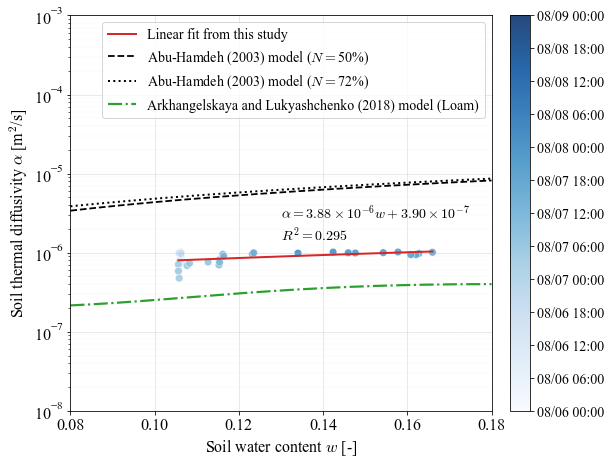

saved figure: 00_output_figures/03_mean_m_alpha_empirical_updated/mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg
saved figure copy: 00_output_figures/mean_m_alpha_empirical_comparison_date_colorbar_large_w_v2.jpg
saved detail: 00_output_figures/03_mean_m_alpha_empirical_updated/mean_m_alpha_empirical_updated_detail.csv
saved summary: 00_output_figures/03_mean_m_alpha_empirical_updated/mean_m_alpha_empirical_updated_summary.csv


In [20]:
mean_m_plot = mean_m_alpha.sort_values("center").reset_index(drop=True)

fig_mean_m_empirical = plt.figure(num=0, figsize=[18, 16])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.18, hspace=0.20)
spec = gridspec.GridSpec(ncols=2, nrows=2, height_ratios=[1, 1])
ax = fig_mean_m_empirical.add_subplot(spec[0, 0])

x = mean_m_plot["w_for_plot"].to_numpy(dtype=float)
y = mean_m_plot["alpha"].to_numpy(dtype=float)
center_times = pd.to_datetime(mean_m_plot["center"])
time_color = (center_times - PLOT_START).dt.total_seconds().to_numpy(dtype=float) / 3600.0
colorbar_min = 0.0
colorbar_max = (PLOT_END - PLOT_START).total_seconds() / 3600.0
colorbar_tick_times = pd.date_range(PLOT_START, PLOT_END, periods=13)
colorbar_tick_positions = (
    (colorbar_tick_times - PLOT_START).total_seconds().to_numpy(dtype=float) / 3600.0
)

scatter = ax.scatter(
    x,
    y,
    c=time_color,
    cmap="Blues",
    vmin=colorbar_min,
    vmax=colorbar_max,
    s=58,
    alpha=0.88,
    edgecolors="white",
    linewidths=0.5,
)

linear_fit_text = "Linear fit unavailable"
exp_fit_text = "Exponential fit unavailable"
if np.nanstd(x) > 0:
    slope, intercept = np.polyfit(x, y, 1)
    x_fit = np.linspace(np.nanmin(x), np.nanmax(x), 100)
    y_fit = slope * x_fit + intercept
    y_pred = slope * x + intercept
    ss_res = np.nansum((y - y_pred) ** 2)
    ss_tot = np.nansum((y - np.nanmean(y)) ** 2)
    r_squared = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    ax.plot(x_fit, y_fit, color="tab:red", linewidth=2, label="Linear fit from this study")
    slope_text = format_sci_latex(slope)
    intercept_sign = "+" if intercept >= 0 else "-"
    intercept_text = format_sci_latex(abs(intercept))
    linear_fit_text = (
        rf"$\alpha = {slope_text}w {intercept_sign} {intercept_text}$"
        "\n"
        f"$R^2 = {r_squared:.3f}$"
    )

# valid_exp = np.isfinite(x) & np.isfinite(y) & (y > 0)
# if valid_exp.sum() >= 2 and np.nanstd(x[valid_exp]) > 0:
#     exp_rate, log_prefactor = np.polyfit(x[valid_exp], np.log(y[valid_exp]), 1)
#     exp_prefactor = np.exp(log_prefactor)
#     x_exp_fit = np.linspace(np.nanmin(x), np.nanmax(x), 100)
#     y_exp_fit = exp_prefactor * np.exp(exp_rate * x_exp_fit)
#     y_exp_pred = exp_prefactor * np.exp(exp_rate * x[valid_exp])
#     exp_ss_res = np.nansum((y[valid_exp] - y_exp_pred) ** 2)
#     exp_ss_tot = np.nansum((y[valid_exp] - np.nanmean(y[valid_exp])) ** 2)
#     exp_r_squared = 1.0 - exp_ss_res / exp_ss_tot if exp_ss_tot > 0 else np.nan
#     ax.plot(x_exp_fit, y_exp_fit, color="tab:orange", linewidth=2, label="Exponential fit from this study")
#     prefactor_text = format_sci_latex(exp_prefactor)
#     exp_rate_text = f"{exp_rate:.2f}"
#     exp_fit_text = (
#         rf"$\alpha = {prefactor_text}e^{{{exp_rate_text}w}}$"
#         "\n"
#         f"Exponential $R^2 = {exp_r_squared:.3f}$"
#     )

# fit_text = linear_fit_text + "\n" + exp_fit_text
fit_text = linear_fit_text

x_min = max(0.01, float(np.nanmin(x)) - 0.10 * float(np.nanmax(x) - np.nanmin(x)))
x_max = min(0.50, float(np.nanmax(x)) + 0.10 * float(np.nanmax(x) - np.nanmin(x)))
if np.isclose(x_min, x_max):
    x_min = max(0.01, x_min - 0.01)
    x_max = min(0.50, x_max + 0.01)
    
x_min = 0.08
x_max = 0.18

x_emp = np.linspace(max(0.01, x_min), min(0.50, x_max), 200)
alpha_emp_lower = abu_hamdeh_2003_alpha(x_emp, EMPIRICAL_N_LOWER)
alpha_emp_upper = abu_hamdeh_2003_alpha(x_emp, EMPIRICAL_N_UPPER)
ax.plot(
    x_emp,
    alpha_emp_lower,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Abu-Hamdeh (2003) model ($N=${EMPIRICAL_N_LOWER:.0f}%)",
)
ax.plot(
    x_emp,
    alpha_emp_upper,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=f"Abu-Hamdeh (2003) model ($N=${EMPIRICAL_N_UPPER:.0f}%)",
)
ax.plot(
    x_emp,
    arkhangelskaya_2018_loam_alpha(x_emp),
    color="tab:green",
    linestyle="-.",
    linewidth=2.2,
    label="Arkhangelskaya and Lukyashchenko (2018) model (Loam)",
)

ax.set_yscale("log")
ax.set_ylim(1e-8, 1e-3)
ax.set_xlim(0.08, 0.18)
ax.set_xlabel("Soil water content $w$ [-]", fontsize=16)
ax.set_ylabel(r"Soil thermal diffusivity $\alpha$ [m$^2$/s]", fontsize=16)
ax.grid(True, which="major", alpha=0.35)
ax.grid(True, which="minor", linestyle="--", linewidth=0.25, alpha=0.25)
ax.text(
    0.50,
    0.42,
    fit_text,
    transform=ax.transAxes,
    fontsize=14,
    va="bottom",
    ha="left",
    bbox=dict(facecolor="none", alpha=0.82, edgecolor="none"),
)
ax.legend(loc=1, fontsize=14)

cbar = fig_mean_m_empirical.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
cbar.set_ticks(colorbar_tick_positions)
cbar.set_ticklabels(colorbar_tick_times.strftime("%m/%d %H:%M"))
cbar.ax.tick_params(labelsize=14)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

fig_mean_m_empirical.savefig(OUT_FIG, dpi=600, bbox_inches="tight")
fig_mean_m_empirical.savefig(OUT_FIG_COPY, dpi=600, bbox_inches="tight")
plt.show()
print("saved figure:", OUT_FIG)
print("saved figure copy:", OUT_FIG_COPY)
print("saved detail:", OUT_DETAIL_CSV)
print("saved summary:", OUT_SUMMARY_CSV)


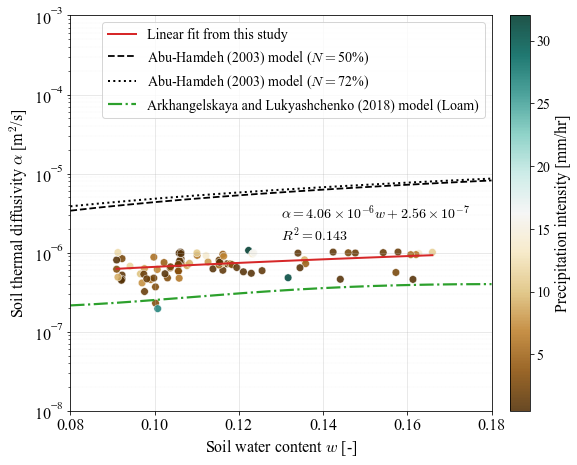

rainy rows across full period = 86
saved figure: 00_output_figures/03_mean_m_alpha_empirical_updated/all_period_rainy_alpha_w_rainfall_colorbar.jpg
saved figure copy: 00_output_figures/all_period_rainy_alpha_w_rainfall_colorbar_v2.jpg
saved detail: 00_output_figures/03_mean_m_alpha_empirical_updated/all_period_rainy_alpha_w_detail.csv


In [21]:
# All-period alpha-w plot: rainy windows only, colored by rainfall amount.
OUT_ALL_RAIN_DETAIL_CSV = OUTPUT_DIR / "all_period_rainy_alpha_w_detail.csv"
OUT_ALL_RAIN_FIG = OUTPUT_DIR / "all_period_rainy_alpha_w_rainfall_colorbar.jpg"
OUT_ALL_RAIN_FIG_COPY = Path("00_output_figures/all_period_rainy_alpha_w_rainfall_colorbar_v2.jpg")

all_rain_alpha = alpha_all[alpha_all["method"] == SELECTED_METHOD].copy()
all_rain_alpha = all_rain_alpha.sort_values("center").reset_index(drop=True)

if all_rain_alpha.empty:
    raise ValueError(f"No rows for {SELECTED_METHOD} in {UPDATED_ALPHA_CSV}")

all_rain_alpha["rain_mm_in_window"] = all_rain_alpha.apply(
    lambda row: rain_mm_in_alpha_window(row, hourly_rainfall), axis=1
)
all_rain_alpha["has_rain_in_window"] = all_rain_alpha["rain_mm_in_window"] > RAIN_THRESHOLD_MM
all_rain_alpha = all_rain_alpha.loc[all_rain_alpha["has_rain_in_window"]].copy().reset_index(drop=True)

if all_rain_alpha.empty:
    raise ValueError("No rainy alpha windows found across the full alpha-estimation period")

all_rain_alpha["w_for_plot"] = all_rain_alpha[SELECTED_WATER_CONTENT_COLUMN].astype(float)
all_rain_alpha.to_csv(OUT_ALL_RAIN_DETAIL_CSV, index=False)

fig_all_rain = plt.figure(num=1, figsize=[18, 16])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.18, hspace=0.20)
spec = gridspec.GridSpec(ncols=2, nrows=2, height_ratios=[1, 1])
ax = fig_all_rain.add_subplot(spec[0, 0])

x = all_rain_alpha["w_for_plot"].to_numpy(dtype=float)
y = all_rain_alpha["alpha"].to_numpy(dtype=float)


rain_color = all_rain_alpha["rain_mm_in_window"].to_numpy(dtype=float)[y > 10**-7]

x = x[y > 10**-7]
y = y[y > 10**-7]


# rain_color = rain_color[y > 10**-7]



scatter = ax.scatter(
    x,
    y,
    c=rain_color,
    cmap="BrBG",
    s=58,
    alpha=0.88,
    edgecolors="white",
    linewidths=0.5,
)

fit_text = "Linear fit unavailable"
if np.nanstd(x) > 0:
    slope, intercept = np.polyfit(x, y, 1)
    x_fit = np.linspace(np.nanmin(x), np.nanmax(x), 100)
    y_fit = slope * x_fit + intercept
    y_pred = slope * x + intercept
    ss_res = np.nansum((y - y_pred) ** 2)
    ss_tot = np.nansum((y - np.nanmean(y)) ** 2)
    r_squared = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    ax.plot(x_fit, y_fit, color="tab:red", linewidth=2, label="Linear fit from this study")
    slope_text = format_sci_latex(slope)
    intercept_sign = "+" if intercept >= 0 else "-"
    intercept_text = format_sci_latex(abs(intercept))
    fit_text = (
        rf"$\alpha = {slope_text}w {intercept_sign} {intercept_text}$"
        "\n"
        f"$R^2 = {r_squared:.3f}$"
    )

x_min = max(0.01, float(np.nanmin(x)) - 0.10 * float(np.nanmax(x) - np.nanmin(x)))
x_max = min(0.50, float(np.nanmax(x)) + 0.10 * float(np.nanmax(x) - np.nanmin(x)))

x_min = 0.08
x_max = 0.18

if np.isclose(x_min, x_max):
    x_min = max(0.01, x_min - 0.01)
    x_max = min(0.50, x_max + 0.01)

x_emp = np.linspace(max(0.01, x_min), min(0.50, x_max), 200)
alpha_emp_lower = abu_hamdeh_2003_alpha(x_emp, EMPIRICAL_N_LOWER)
alpha_emp_upper = abu_hamdeh_2003_alpha(x_emp, EMPIRICAL_N_UPPER)
ax.plot(
    x_emp,
    alpha_emp_lower,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Abu-Hamdeh (2003) model ($N=${EMPIRICAL_N_LOWER:.0f}%)",
)
ax.plot(
    x_emp,
    alpha_emp_upper,
    color="black",
    linestyle=":",
    linewidth=2.0,
    label=f"Abu-Hamdeh (2003) model ($N=${EMPIRICAL_N_UPPER:.0f}%)",
)
ax.plot(
    x_emp,
    arkhangelskaya_2018_loam_alpha(x_emp),
    color="tab:green",
    linestyle="-.",
    linewidth=2.2,
    label="Arkhangelskaya and Lukyashchenko (2018) model (Loam)",
)

ax.set_yscale("log")
ax.set_ylim(1e-8, 1e-3)
ax.set_xlim(0.08, 0.18)
ax.set_xlabel("Soil water content $w$ [-]", fontsize=16)
ax.set_ylabel(r"Soil thermal diffusivity $\alpha$ [m$^2$/s]", fontsize=16)
ax.grid(True, which="major", alpha=0.35)
ax.grid(True, which="minor", linestyle="--", linewidth=0.25, alpha=0.25)
ax.text(
    0.50,
    0.42,
    fit_text,
    transform=ax.transAxes,
    fontsize=14,
    va="bottom",
    ha="left",
    bbox=dict(facecolor="none", alpha=0.82, edgecolor="none"),
)
ax.legend(loc=1, fontsize=14)

cbar = fig_all_rain.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Precipitation intensity [mm/hr]", fontsize=16)
cbar.ax.tick_params(labelsize=14)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())

fig_all_rain.savefig(OUT_ALL_RAIN_FIG, dpi=600, bbox_inches="tight")
fig_all_rain.savefig(OUT_ALL_RAIN_FIG_COPY, dpi=600, bbox_inches="tight")
plt.show()
print(f"rainy rows across full period = {len(all_rain_alpha)}")
print("saved figure:", OUT_ALL_RAIN_FIG)
print("saved figure copy:", OUT_ALL_RAIN_FIG_COPY)
print("saved detail:", OUT_ALL_RAIN_DETAIL_CSV)
